In [1]:
#### RUN THIS CELL TO IMPORT REQUIRED LIBRARIES ####
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import ellipk
import matplotlib.ticker as mtick   
import csv
# Change any of the constants below to your desired values.
# The code will automatically calculate the GF for the given parameters and write the results to a CSV file named 'sensor_GF_v={poisson's ratio used}.csv'. 
# Please manually rename any existing 'sensor_GF_v={poisson's ratio used}.csv' file to avoid overwriting previous results.

Function and Test Samples

Length: 10 mm, Gap: 0.42 mm, Width: 0.31 mm, EndGap: 0.5 mm, GF_Y: -0.3470, GF_X: 0.9998
Length: 10 mm, Gap: 0.69 mm, Width: 0.31 mm, EndGap: 0.5 mm, GF_Y: -0.3463, GF_X: 0.9997
Length: 10 mm, Gap: 1.03 mm, Width: 0.31 mm, EndGap: 0.5 mm, GF_Y: -0.3458, GF_X: 0.9997
Length: 10 mm, Gap: 0.42 mm, Width: 0.31 mm, EndGap: 0.5 mm, GF_Y: -0.3470, GF_X: 0.9998
Length: 15 mm, Gap: 0.42 mm, Width: 0.31 mm, EndGap: 0.5 mm, GF_Y: -0.3471, GF_X: 0.9998
Length: 20 mm, Gap: 0.42 mm, Width: 0.31 mm, EndGap: 0.5 mm, GF_Y: -0.3471, GF_X: 0.9999
Length: 10 mm, Gap: 0.42 mm, Width: 0.31 mm, EndGap: 0.5 mm, GF_Y: -0.3470, GF_X: 0.9998
Length: 10 mm, Gap: 0.42 mm, Width: 0.56 mm, EndGap: 0.5 mm, GF_Y: -0.3464, GF_X: 0.9997
Length: 10 mm, Gap: 0.42 mm, Width: 0.7 mm, EndGap: 0.5 mm, GF_Y: -0.3462, GF_X: 0.9996
Length: 10 mm, Gap: 0.42 mm, Width: 0.31 mm, EndGap: 0.5 mm, GF_Y: -0.3470, GF_X: 0.9998
Length: 10 mm, Gap: 0.42 mm, Width: 0.31 mm, EndGap: 0.7 mm, GF_Y: -0.3471, GF_X: 0.9998
Length: 10 mm, Gap: 0.

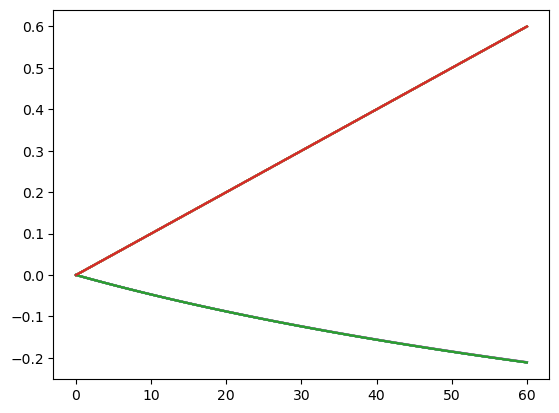

In [17]:
#### CONSTANTS (CHANGE THESE) ####
epsilon_r = 23.2       # Relative permittivity of the substrate 23.2
epsilon_0 = 8.854e-12  # Permittivity of free space (F/m)
nu = 0.5         # Poisson's ratio
t = 0.02               # Electrode thickness (mm)
n = 6                  # Number of electrode digits
strain = 60
#### ASSIGN STRAIN VALUES TO MEMORY (DO NOT TOUCH) ####
e_x = np.linspace(0, strain, 100) # Strain values from 0 to 100%
e_y = np.linspace(0, strain, 100) # Strain values from 0 to 100%


# Gauge factor calculation function (X and Y direction conventions are flipped in this function compared to your work, but I account for it at the end when writing to the CSV file)
def GF(l, g, w, h):                         
    k = np.cos(np.pi/2 * w / (g + w)) # Elliptic integral parameter
    k_prime = np.sqrt(1 - k**2)       # Complementary elliptic integral parameter

    ## With elliptic integral ##
    C_t = (n-1) * (1 * epsilon_0 * l) / 2 * ellipk(k_prime) / ellipk(k)         # Fringe capacitance, top
    C_s = (n-1) * (epsilon_r * epsilon_0 * l) / 2 * ellipk(k_prime) / ellipk(k) # Fringe capacitance, substrate
    C_m = epsilon_0 * t * (n-1) * (w/h + l/g)                                   # Parallel capacitance, matrix
    C_0 = C_t + C_s + C_m                                                       # Total capacitance

    # After x-strain e_x
    lambda_x = 1 + e_x/100 # Stretch ratio in x-direction
    lambda_y = lambda_x**(-nu) # Stretch ratio in y-direction
    C_tx = (n-1) * (epsilon_0 * l * lambda_y) / 2 * ellipk(k_prime) / ellipk(k)                                    # Fringe capacitance, top
    C_sx = (n-1) * (epsilon_r * epsilon_0 * l * lambda_y) / 2 * ellipk(k_prime) / ellipk(k)                        # Fringe capacitance, substrate       
    C_mx = epsilon_0 * t * lambda_y * (n-1) * (w*lambda_x/(h*lambda_y) + l*(lambda_y/(g*lambda_x)))  # Parallel capacitance, matrix

    C_x = C_tx + C_sx + C_mx                 # Total capacitance after x-strain
    C_rx = (C_x - C_0)/C_0                   # Relative change in capacitance
    plt.plot(e_x, C_rx)
    mx, b = np.polyfit(e_x/100, C_rx, 1)     # Linear fit to find sensitivity

    # After y-strain e_y
    lambda_y = 1 + e_y/100 # Stretch ratio in y-direction
    lambda_x = lambda_y**(-nu) # Stretch ratio in x-direction
    C_ty = (n-1) * (epsilon_0 * l * lambda_y) / 2 * ellipk(k_prime) / ellipk(k)                                         # Fringe capacitance, top
    C_sy = (n-1) * (epsilon_r * epsilon_0 * l * lambda_y) / 2 * ellipk(k_prime) / ellipk(k)                             # Fringe capacitance, substrate 
    C_my = epsilon_0 * t * lambda_x * (n-1) * (w*lambda_x/(h*lambda_y) + l*(lambda_y/(g*lambda_x)))     # Parallel capacitance, matrix
    
    C_y = C_ty + C_sy + C_my             # Total capacitance after y-strain
    C_ry = (C_y-C_0) / C_0               # Relative change in capacitance
    plt.plot(e_y, C_ry)
    my, b = np.polyfit(e_y/100, C_ry, 1) # Linear fit to find sensitivity
    
    return l, g, w, h, mx, my

#### TEST PARAMETERS (length, gap, width, endgap) (CHANGE AS REQUIRED) ####
sensor_params = [
    # Changing gap
  [10, 0.42, 0.31, 0.50],
  [10, 0.69, 0.31, 0.50],
  [10, 1.03, 0.31, 0.50],
    # Changing length
  [10, 0.42, 0.31, 0.50],
  [15, 0.42, 0.31, 0.50],
  [20, 0.42, 0.31, 0.50],
    # Changing width
  [10, 0.42, 0.31, 0.50],
  [10, 0.42, 0.56, 0.50],
  [10, 0.42, 0.70, 0.50],
    # Changing endgap
  [10, 0.42, 0.31, 0.50],
  [10, 0.42, 0.31, 0.70],
  [10, 0.42, 0.31, 1.05]
]

#### WRITE RESULTS TO CSV FILE ####
headers = ['Length (mm)', 'Gap (mm)', 'Width (mm)', 'EndGap (mm)', 'GF_Y', 'GF_X'] # I use your convention for directions X and Y here. 
with open(f'sensor_GF_v={nu}.csv', 'w', newline='') as csvfile:
    writer = csv.writer(csvfile)
    writer.writerow(headers)
    for params in sensor_params:
        result = GF(*params)
        writer.writerow([result[0], result[1], result[2], result[3], result[4], result[5]])

        # Results displayed in the console for quick reference with code below
        print(f"Length: {result[0]} mm, Gap: {result[1]} mm, Width: {result[2]} mm, EndGap: {result[3]} mm, GF_Y: {result[4]:.4f}, GF_X: {result[5]:.4f}")